# 01 — EDA: C-MAPSS FD001

Exploratory analysis for the turbofan RUL / survival-analysis project. See
`docs/project_brief.md` for full scope and rationale.

**Subset:** FD001 (single operating condition, single fault mode) — the core
subset for this project. FD002–FD004 use the same loader
(`turbofan_rul.data_loading`) and are covered later, in
`09_fd002_fd003_generalization_check.ipynb` and `10_fd004_full_pipeline.ipynb`;
see `project_brief.md` Section 3 for the scope decision.

**Data source:** downloaded programmatically (not a manual save-as-CSV step)
from a GitHub mirror of the original NASA files, with row and engine counts
checked against reference statistics, and every engine's cycles checked to run
contiguously from 1, on load — see `data_loading.py` for the reasoning.

This notebook:
1. Downloads and loads FD001 (train, test, RUL)
2. Plots raw sensor trajectories for a handful of engines
3. Computes per-sensor variance and flags near-constant sensors
4. Correlation heatmap across the remaining sensors
5. Checks operating-condition variability (confirms FD001 is single-regime)
6. Writes out a documented kept/dropped sensor list for `features.py`


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, plotting

plotting.style()
SUBSET = "FD001"
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 1. Acquire data

In [2]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)

print(f"train: {cmapss.train.shape}  ({cmapss.train['unit_number'].nunique()} engines)")
print(f"test:  {cmapss.test.shape}  ({cmapss.test['unit_number'].nunique()} engines)")
print(f"rul:   {cmapss.rul.shape}")

train: (20631, 26)  (100 engines)
test:  (13096, 26)  (100 engines)
rul:   (100, 2)


## 2. Inspect raw structure

In [3]:
display(cmapss.train.head())
display(cmapss.train.describe().T)

,unit_number,time_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
time_cycles,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op_setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op_setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


## 3. Raw sensor trajectories for a handful of engines

Plotting a subset of sensors across a handful of engines (colored by engine
unit) to visually confirm the expected pattern: sensors should look roughly
flat/noisy early in an engine's life and show a clear degradation trend in
the cycles leading up to failure. This is the visual sanity check that the
dataset behaves the way the survival-analysis framing assumes.

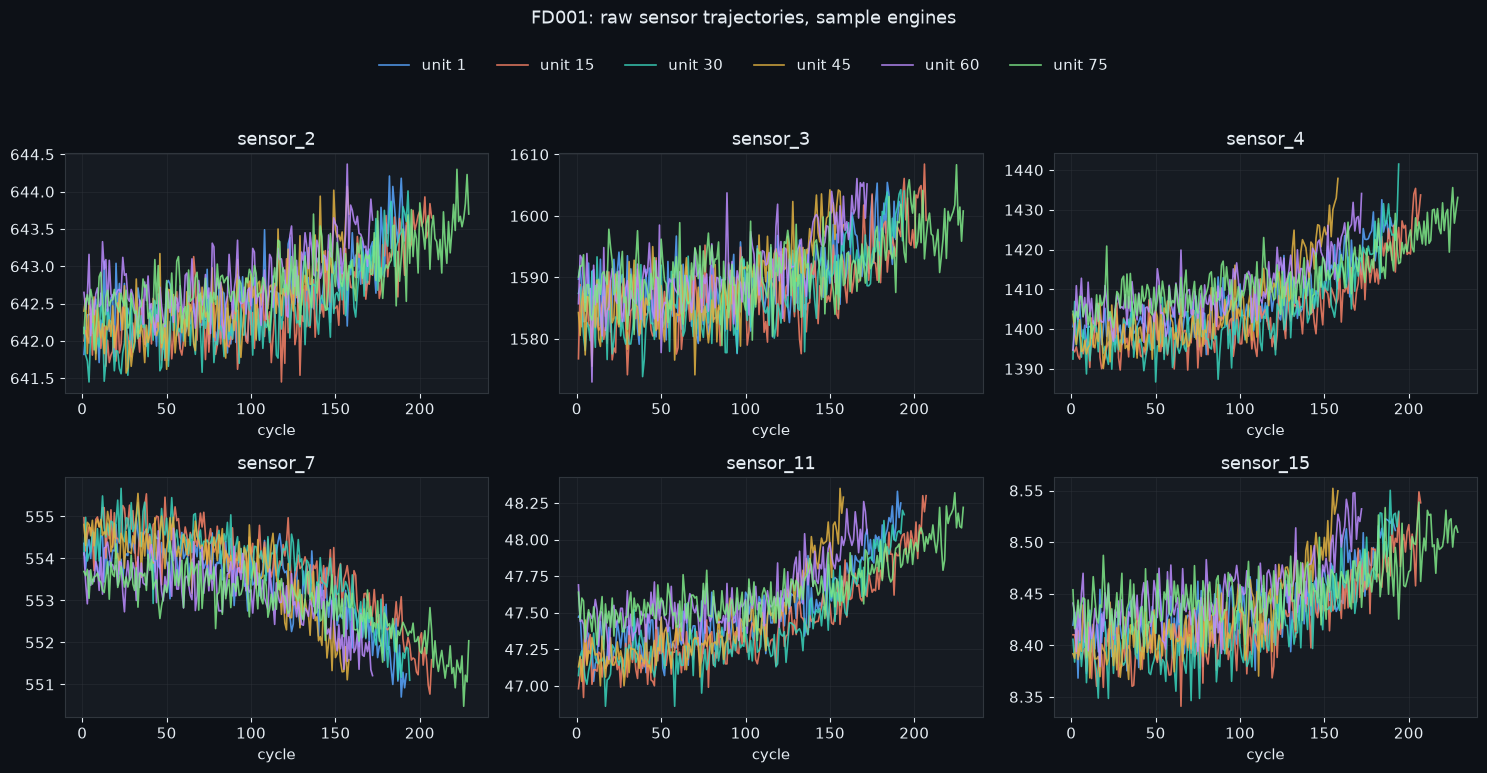

In [4]:
sample_units = [1, 15, 30, 45, 60, 75]
sensors_to_plot = ["sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_11", "sensor_15"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=False)
for ax, sensor in zip(axes.flat, sensors_to_plot):
    for i, unit in enumerate(sample_units):
        traj = cmapss.train[cmapss.train.unit_number == unit]
        ax.plot(traj["time_cycles"], traj[sensor],
                color=plotting.PALETTE[i % len(plotting.PALETTE)],
                alpha=0.85, linewidth=1.2, label=f"unit {unit}")
    ax.set_title(sensor)
    ax.set_xlabel("cycle")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(sample_units),
           bbox_to_anchor=(0.5, 1.05), frameon=False)
fig.suptitle(f"{SUBSET}: raw sensor trajectories, sample engines", y=1.1)
fig.tight_layout()
plt.show()

## 4. Per-sensor variance → identify near-constant sensors

A sensor that barely moves across an engine's whole run-to-failure trajectory
carries no degradation signal and just adds noise/dimensionality to the
feature set. We use **coefficient of variation** (std / mean) rather than
raw variance, since raw sensor units differ by orders of magnitude (e.g.
pressure in psia vs. a normalized setting near 1.0) and comparing raw
variances across sensors would be comparing different units, not informativeness.

In [5]:
sensor_cols = [c for c in cmapss.train.columns if c.startswith("sensor_")]

variance_summary = pd.DataFrame({
    "mean": cmapss.train[sensor_cols].mean(),
    "std": cmapss.train[sensor_cols].std(),
})
variance_summary["cv"] = (variance_summary["std"] / variance_summary["mean"].abs()).round(6)
variance_summary = variance_summary.sort_values("cv")

CV_THRESHOLD = 1e-4  # sensors below this are treated as effectively constant for FD001
flat_sensors = variance_summary[variance_summary["cv"] < CV_THRESHOLD].index.tolist()

display(variance_summary)
print(f"\n{len(flat_sensors)} near-constant sensors flagged for dropping: {flat_sensors}")

,mean,std,cv
sensor_1,518.670000,0.000000e+00,0.000000
sensor_5,14.620000,5.329200e-15,0.000000
sensor_16,0.030000,3.469531e-18,0.000000
sensor_10,1.300000,0.000000e+00,0.000000
sensor_19,100.000000,0.000000e+00,0.000000
sensor_18,2388.000000,0.000000e+00,0.000000
sensor_8,2388.096652,7.098548e-02,0.000030
sensor_13,2388.096152,7.191892e-02,0.000030
sensor_6,21.609803,1.388985e-03,0.000064
sensor_2,642.680934,5.000533e-01,0.000778



9 near-constant sensors flagged for dropping: ['sensor_1', 'sensor_5', 'sensor_16', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_8', 'sensor_13', 'sensor_6']


**A caveat on this screen.** Coefficient of variation divides by the mean, so a
sensor with a large mean can get a tiny CV even if it does move with
degradation. `sensor_8` and `sensor_13` (both near 2388, CV ≈ 3×10⁻⁵) are
dropped here mainly for that reason; much of the C-MAPSS literature keeps
them, in the commonly used 14-sensor FD001 set. They are dropped
deliberately in this project and the decision is recorded in the output
file below, but it is a judgment call, not a proof that they carry no
signal. A screen based on each sensor's trend against remaining life would
be the stricter test.

## 5. Correlation heatmap across remaining sensors

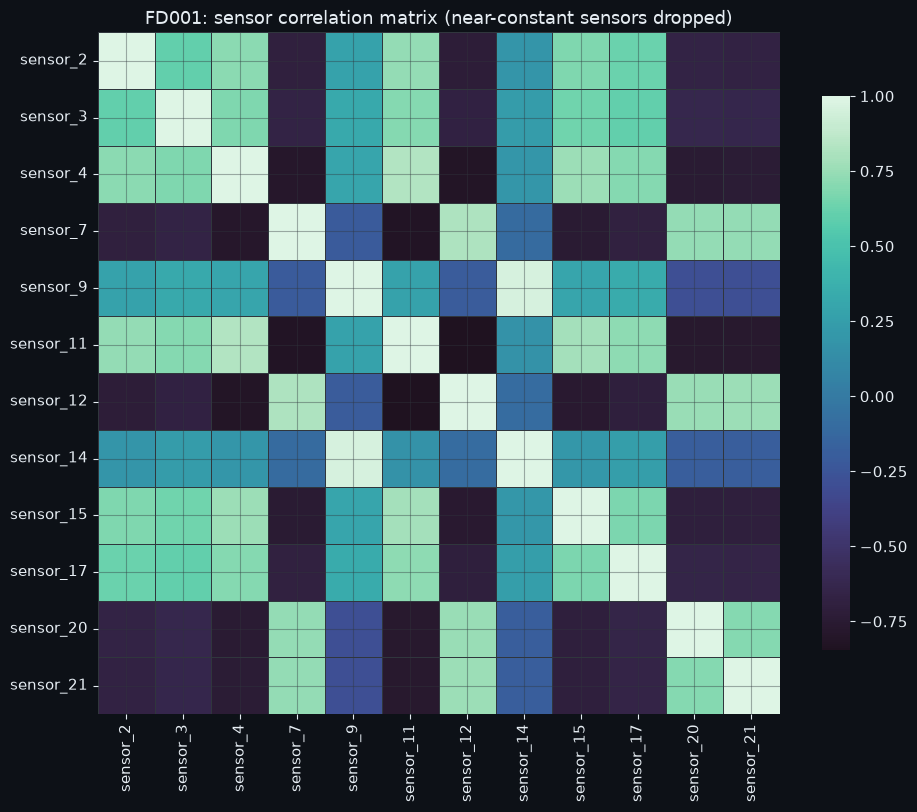

Highly correlated sensor pairs (|r| > 0.95):


sensor_9  sensor_14    0.963157
dtype: float64

In [6]:
kept_sensors = [s for s in sensor_cols if s not in flat_sensors]
corr = cmapss.train[kept_sensors].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="mako", center=0, square=True, linewidths=0.4,
            linecolor=plotting.GRID, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title(f"{SUBSET}: sensor correlation matrix (near-constant sensors dropped)")
plt.show()

# flag highly redundant pairs for the feature-engineering writeup, not auto-dropped here --
# redundancy alone isn't a reason to drop a sensor (see notes below)
HIGH_CORR_THRESHOLD = 0.95
redundant_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .loc[lambda s: s.abs() > HIGH_CORR_THRESHOLD]
    .sort_values(ascending=False)
)
print("Highly correlated sensor pairs (|r| > 0.95):")
display(redundant_pairs)

Redundant pairs are **flagged, not automatically dropped** — two sensors
moving together during degradation isn't necessarily wasted signal (e.g. one
may be noisier, or degrade earlier), and tree-based / regularized models
downstream handle collinearity reasonably well. The list above is recorded
for the feature-engineering writeup and revisited if a specific model
(e.g. Cox PH, which is more sensitive to collinearity than Random Survival
Forest) shows instability.

## 6. Operating condition variability

FD001 is documented as single-regime, so `op_setting_1..3` should show
essentially no meaningful spread — confirming this now matters because it's
exactly the assumption that **breaks** for FD002/FD004 (6 operating
conditions), which is why those subsets need an operating-condition
clustering + within-cluster normalization step in `features.py` that FD001
does not.

,op_setting_1,op_setting_2,op_setting_3
count,20631.000000,20631.000000,20631.0
mean,-0.000009,0.000002,100.0
std,0.002187,0.000293,0.0
min,-0.008700,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,0.000000,0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008700,0.000600,100.0


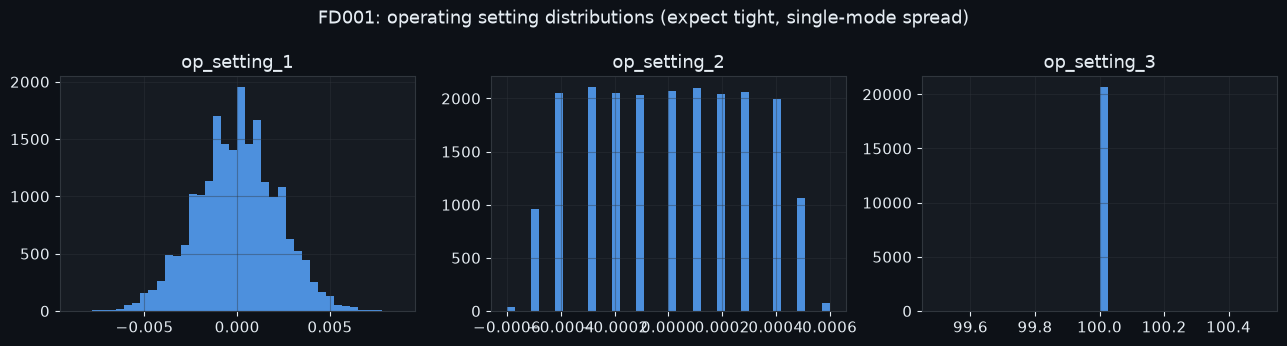

In [7]:
op_cols = ["op_setting_1", "op_setting_2", "op_setting_3"]
display(cmapss.train[op_cols].describe())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, op_cols):
    ax.hist(cmapss.train[col], bins=40, color=plotting.C0, alpha=0.85)
    ax.set_title(col)
fig.suptitle(f"{SUBSET}: operating setting distributions (expect tight, single-mode spread)")
fig.tight_layout()
plt.show()

## 7. Output: documented kept/dropped sensor list

This becomes a direct input to `features.py` — feature engineering reads
this file rather than re-deriving the sensor list, so the EDA decision and
the pipeline can't silently drift apart.

In [8]:
sensor_selection = {
    "subset": SUBSET,
    "cv_threshold": CV_THRESHOLD,
    "kept_sensors": kept_sensors,
    "dropped_sensors": {
        s: "near-constant across all engines (coefficient of variation below threshold); "
           "carries no degradation signal for this subset"
        for s in flat_sensors
    },
    "flagged_redundant_pairs": [
        {"sensor_a": a, "sensor_b": b, "correlation": round(float(v), 4)}
        for (a, b), v in redundant_pairs.items()
    ],
}

out_path = PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json"
with open(out_path, "w") as f:
    json.dump(sensor_selection, f, indent=2)

print(f"Wrote sensor selection to {out_path}")
print(f"Kept {len(kept_sensors)} / {len(sensor_cols)} sensors.")

Wrote sensor selection to ..\data\processed\fd001_sensor_selection.json
Kept 12 / 21 sensors.
